# 03 - Wear estimation (Random Forest regressor)

**Question:** *how worn is the tool right now?*

Measuring wear needs to stop the machine and use a microscope. This model is a **virtual sensor**:
it estimates the flank wear (mm) from the motor current, vibration and acoustic emission, while the machine runs.

In [1]:
import sys, json
sys.path.append("..")  # to import features.py from the project root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from features import FEATURES, SIGNAL_FEATURES, WEAR_LIMIT_MM

In [2]:
df = pd.read_csv("../data/milling_features.csv")
print(len(df), "runs from", df["case"].nunique(), "tools")

166 runs from 16 tools


In [3]:
data = df.dropna(subset=["wear_mm"])
X, y, tools = data[FEATURES], data["wear_mm"], data["case"]
print(len(data), "runs with a wear measurement")

146 runs with a wear measurement


## Honest evaluation: leave-one-tool-out

The runs of one tool are strongly linked to each other. A random split would put runs of the same tool
in train **and** test, and the score would look much better than reality.
Here the model is always tested on **tools it has never seen** (`GroupKFold` grouped by `case`).

In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error

model = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)
predicted = cross_val_predict(model, X, y, groups=tools, cv=GroupKFold(n_splits=tools.nunique()))

mae = mean_absolute_error(y, predicted)
baseline_mae = mean_absolute_error(y, np.full(len(y), y.mean()))
print(f"MAE: {mae:.3f} mm   (always guessing the average: {baseline_mae:.3f} mm)")

MAE: 0.108 mm   (always guessing the average: 0.197 mm)


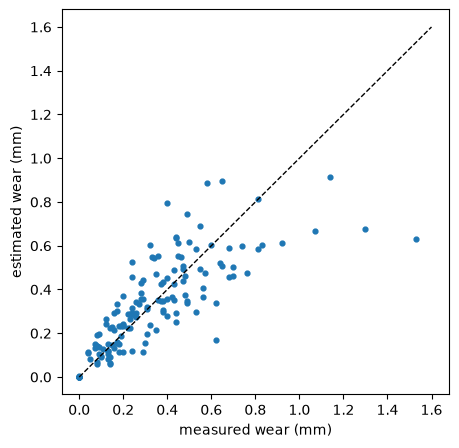

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y, predicted, s=12)
ax.plot([0, 1.6], [0, 1.6], "k--", lw=1)
ax.set_xlabel("measured wear (mm)"); ax.set_ylabel("estimated wear (mm)");

## Train on all tools and look at the important sensors

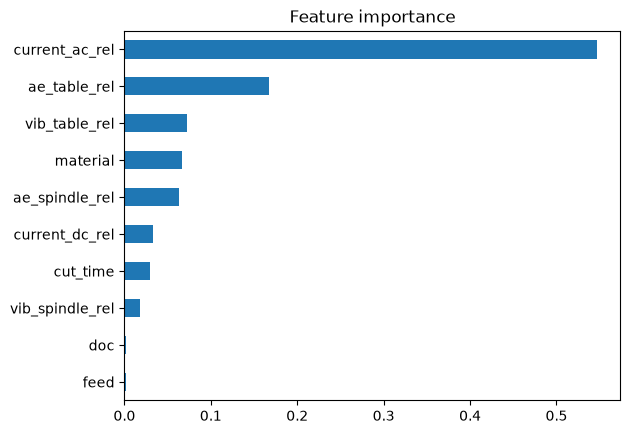

In [6]:
model.fit(X, y)
pd.Series(model.feature_importances_, index=FEATURES).sort_values().plot.barh(title="Feature importance");

## Save

In [7]:
metrics = {"name": "Random Forest regressor", "task": "Tool wear estimation (mm)",
           "score": f"MAE {mae:.3f} mm on unseen tools (baseline {baseline_mae:.3f})"}
joblib.dump(model, "../models/wear_estimator.joblib")
json.dump(metrics, open("../models/wear_estimator_metrics.json", "w"), indent=2)
metrics

{'name': 'Random Forest regressor',
 'task': 'Tool wear estimation (mm)',
 'score': 'MAE 0.108 mm on unseen tools (baseline 0.197)'}